# Minería de Datos · Sesión 5: Análisis Exploratorio de Datos (EDA)
## Proyecto: Hurto de Vehículos y Capacidad Policial en Colombia
**Docente:** Esteban Ernesto Morales Castro · UNIMINUTO Ibagué · 2026-2

---
### Objetivos de la sesión implementados en el proyecto:
1. **Calcular e interpretar** las tres familias de medidas estadísticas (tendencia central, dispersión y forma).
2. **Demostrar la lección de Anscombe**: Por qué los resúmenes numéricos (`describe()`) son ciegos a la distribución real y cómo los gráficos revelan patrones ocultos.
3. **Cuantificar rigurosamente observaciones atípicas** mediante la regla del Rango Intercuartílico (IQR: $Q_3 + 1.5 \times IQR$).
4. **Construir la galería completa de visualizaciones** siguiendo las Buenas Prácticas (títulos-hallazgo, unidades explícitas, ejes desde cero, sin gráficos 3D engañosos).
5. **Interpretar la correlación lineal de Pearson ($r$)** y diferenciar rigurosamente correlación de causalidad.
6. **Consolidar hallazgos accionables** en el formato estándar: *Hallazgo + Evidencia Estadística + Acción de Política Pública*.


## 1. Importación de Librerías y Clase Modular EDA
Se carga la clase `EDA` desde `src.eda` que encapsula todo el pipeline exploratorio del proyecto.

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sys.path.append("..")
from src.eda import EDA

eda = EDA("../dataset/dataset_integrado.csv")
df = eda.cargar()
print(f"Dataset cargado: {df.shape[0]:,} registros y {df.shape[1]} variables.")

Dataset cargado: 54,428 registros y 8 variables.


## 2. Diagnóstico de Calidad de Datos (CRISP-DM: Entendimiento de Datos)
Verificación de completitud, ausencia de nulos y tipología de las variables consolidadas en la etapa de integración.

In [2]:
diag = eda.diagnostico_calidad()

DIAGNÓSTICO DE CALIDAD DE DATOS · DATASET INTEGRADO
Dimensiones      : 54,428 registros × 8 columnas
Duplicados exactos: 0
Valores nulos    : 0 (Completitud del 100% garantizada en integración)

Estructura de variables:
  • AÑO                      : int64
  • CODIGO_DANE_MUNICIPIO    : int64
  • DEPARTAMENTO             : object
  • MUNICIPIO                : object
  • TIPO_VEHICULO            : object
  • VEHICULOS_REGISTRADOS    : float64
  • VEHICULOS_HURTADOS       : float64
  • VEHICULOS_RECUPERADOS    : float64


## 3. El Gancho: ¿Por qué no podemos confiar ciegamente en `describe()`?
### La lección del Cuarteto de Anscombe aplicada a la criminalidad vehicular en Colombia
Si un analista se limita a mirar la media de `VEHICULOS_HURTADOS` (7.08 unidades), concluiría erróneamente que cada municipio del país sufre ~7 hurtos anuales.
Sin embargo, al calcular la mediana descubrimos que es **0.00**, con una asimetría de **+6.29**. La media está distorsionada por menos del 15% de los municipios (las grandes áreas metropolitanas).

In [3]:
s_hurto = df["VEHICULOS_HURTADOS"]
print(f"Media aritmética : {s_hurto.mean():.2f} (engañosa por colas largas)")
print(f"Mediana (robusta): {s_hurto.median():.2f} (el 50% de los municipios reporta 0 hurtos)")
print(f"Asimetría (Skew) : +{s_hurto.skew():.2f} (cola derecha extrema)")
print(f"Curtosis         : {s_hurto.kurtosis():.2f} (distribución hiperleptocúrtica)")

Media aritmética : 7.08 (engañosa por colas largas)
Mediana (robusta): 0.00 (el 50% de los municipios reporta 0 hurtos)
Asimetría (Skew) : +6.29 (cola derecha extrema)
Curtosis         : 42.10 (distribución hiperleptocúrtica)


## 4. Las Tres Familias de Medidas Estadísticas Descriptivas
Se calculan formalmente para las 3 variables cuantitativas continuas del proyecto:
- **Tendencia central**: Media ($\bar{x}$), Mediana ($M$), Moda.
- **Dispersión**: Desviación estándar ($s$), Rango, Cuartiles ($Q_1, Q_3$) y Rango Intercuartílico ($IQR$).
- **Forma**: Coeficiente de Asimetría (Fisher-Pearson) y Curtosis.

In [4]:
stats = eda.estadisticas_descriptivas()

ESTADÍSTICAS DESCRIPTIVAS: TENDENCIA CENTRAL, DISPERSIÓN Y FORMA

--- Variable: VEHICULOS_HURTADOS ---
  • Media (x̄)              : 7.08
  • Mediana (M)            : 0.00  <- Medida robusta recomendada
  • Moda                   : 0.00
  • Desviación estándar (s): 28.03
  • Rango [Min, Max]       : [0.0, 224.0] (Rango = 224.0)
  • Cuartiles [Q1, Q3]     : [0.0, 2.0] -> IQR = 2.0
  • Límite superior IQR    : 5.0
  • Asimetría (Skewness)   : +6.29 (Cola derecha extremadamente alargada)
  • Curtosis               : 42.10 (Distribución fuertemente leptocúrtica)
  • Outliers IQR           : 8,344 registros (15.33%)

--- Variable: VEHICULOS_RECUPERADOS ---
  • Media (x̄)              : 3.06
  • Mediana (M)            : 0.00  <- Medida robusta recomendada
  • Moda                   : 0.00
  • Desviación estándar (s): 9.18
  • Rango [Min, Max]       : [0.0, 68.0] (Rango = 68.0)
  • Cuartiles [Q1, Q3]     : [0.0, 2.0] -> IQR = 2.0
  • Límite superior IQR    : 5.0
  • Asimetría (Skewness)   : +

## 5. Cuantificación Rigurosa de Outliers (Regla IQR)
Siguiendo la regla de Tukey para diagramas de caja y bigotes:
$$\text{Límite Superior} = Q_3 + 1.5 \times IQR$$
Cualquier observación que supere este umbral es clasificada formalmente como dato atípico.

In [5]:
resumen_outliers = eda.cuantificar_outliers_iqr()
print(f"Umbral Q3 + 1.5xIQR : {resumen_outliers['limite_superior']:.1f} hurtos")
print(f"Total de outliers    : {resumen_outliers['total_outliers']:,} ({resumen_outliers['porcentaje_outliers']:.2f}% de los datos)")
print("\nTop municipios con mayor concentración en registros atípicos:")
for m, v in resumen_outliers['top_municipios_atípicos'].items():
    print(f"  • {m:<15}: {v:,.0f} hurtos acumulados")

Umbral Q3 + 1.5xIQR : 5.0 hurtos
Total de outliers    : 8,344 (15.33% de los datos)

Top municipios con mayor concentración en registros atípicos:
  • MEDELLIN       : 10,752 hurtos acumulados
  • BOGOTA D.C.    : 10,752 hurtos acumulados
  • CALI           : 10,752 hurtos acumulados
  • BARRANQUILLA   : 10,677 hurtos acumulados
  • BELLO          : 8,979 hurtos acumulados
  • POPAYAN        : 8,400 hurtos acumulados
  • CUCUTA         : 7,898 hurtos acumulados
  • PASTO          : 7,571 hurtos acumulados
  • CARTAGENA DE INDIAS: 6,705 hurtos acumulados
  • ITAGUI         : 6,687 hurtos acumulados


## 6. Análisis Bivariado y Cálculo de Tasas Operativas
Contraste de la variable objetivo según tipología vehicular y departamentos críticos:
- Tasa de victimización vehicular: Hurto por cada mil registrados.
- Tasa de efectividad operativa: $\frac{\text{Recuperados}}{\text{Hurtados}} \times 100\%$.

In [6]:
tasas = eda.analisis_bivariado_y_tasas()
print("=== TASAS POR TIPOLOGÍA VEHICULAR ===")
display(tasas["resumen_tipo"])
print("\n=== TOP 10 DEPARTAMENTOS Y TASA DE RECUPERACIÓN ===")
display(tasas["top_departamentos"])

=== TASAS POR TIPOLOGÍA VEHICULAR ===


,TIPO_VEHICULO,VEHICULOS_REGISTRADOS,VEHICULOS_HURTADOS,VEHICULOS_RECUPERADOS,TASA_RECUPERACION_%,TASA_HURTO_X_1000_REG
0,AUTOMOTOR,6.149472e+06,93589.0,46275.0,49.44,15.22
1,MOTOCICLETA,1.268916e+07,291905.0,120544.0,41.30,23.00



=== TOP 10 DEPARTAMENTOS Y TASA DE RECUPERACIÓN ===


,DEPARTAMENTO,VEHICULOS_HURTADOS,VEHICULOS_RECUPERADOS,VEHICULOS_REGISTRADOS,TASA_RECUPERACION_%
0,ANTIOQUIA,56008.0,20840.0,4.877323e+06,37.21
1,VALLE DEL CAUCA,42551.0,14337.0,1.877868e+06,33.69
2,CAUCA,28961.0,13815.0,4.571545e+05,47.70
3,ATLANTICO,23124.0,7034.0,1.307352e+06,30.42
4,HUILA,20003.0,7050.0,5.698229e+05,35.24
5,SANTANDER,18387.0,7068.0,1.025388e+06,38.44
6,NARINO,17718.0,11238.0,4.874922e+05,63.43
7,CUNDINAMARCA,17330.0,10487.0,1.763435e+06,60.51
8,CESAR,15809.0,5865.0,2.930646e+05,37.10
9,NORTE DE SANTANDER,15508.0,6789.0,5.220395e+05,43.78


## 7. Matriz de Correlación de Pearson y Causalidad
### Fuerza y Dirección del Coeficiente $r$
- Pearson mide el grado de asociación lineal entre variables continuas.
- **Correlación NO implica causalidad**: Un coeficiente fuerte ($r = 0.61$) entre hurtos y recuperaciones policiales evidencia co-ocurrencia operativa en áreas de alta densidad urbana, no que los hurtos causen directamente las recuperaciones.

In [7]:
corr_dict = eda.calcular_correlaciones()
print("Matriz de Correlación de Pearson:")
display(corr_dict["matriz"].round(4))
print("\nInterpretación Hurto vs Recuperación:")
for k, v in corr_dict["hurto_vs_recuperacion"].items():
    print(f"  • {k}: {v}")

Matriz de Correlación de Pearson:


,AÑO,VEHICULOS_REGISTRADOS,VEHICULOS_HURTADOS,VEHICULOS_RECUPERADOS
AÑO,1.0000,0.1231,0.1684,0.2580
VEHICULOS_REGISTRADOS,0.1231,1.0000,0.3914,0.3836
VEHICULOS_HURTADOS,0.1684,0.3914,1.0000,0.6061
VEHICULOS_RECUPERADOS,0.2580,0.3836,0.6061,1.0000



Interpretación Hurto vs Recuperación:
  • r: 0.6061162247921101
  • fuerza: Fuerte (0.5 - 0.7)
  • direccion: Positiva (+)
  • lectura: A mayor número de hurtos, mayor volumen de recuperaciones policiales (co-ocurrencia operativa en grandes capitales).


## 8. Galería Completa de Visualizaciones (Buenas Prácticas Sesión 5)
Generación y visualización interactiva de las 8 figuras exportadas en alta resolución (150 DPI).

In [8]:
figuras = eda.generar_galeria_figuras(carpeta_salida="figuras")
print(f"Se generaron {len(figuras)} figuras con títulos-hallazgo y estándares institucionales.")


GALERÍA DE FIGURAS EDA GENERADA CON ÉXITO
  ✓ fig_hist_hurtos.png -> figuras/fig_hist_hurtos.png
  ✓ fig_box_hurtos.png -> figuras/fig_box_hurtos.png
  ✓ fig_barras_departamentos.png -> figuras/fig_barras_departamentos.png
  ✓ fig_scatter_hurto_vs_recuperacion.png -> figuras/fig_scatter_hurto_vs_recuperacion.png
  ✓ fig_heatmap_correlaciones.png -> figuras/fig_heatmap_correlaciones.png
  ✓ fig_matriz_dispersion.png -> figuras/fig_matriz_dispersion.png
  ✓ fig_box_hurto_tipo_vehiculo.png -> figuras/fig_box_hurto_tipo_vehiculo.png
  ✓ fig_tendencia_temporal_tasa_recuperacion.png -> figuras/fig_tendencia_temporal_tasa_recuperacion.png
Se generaron 8 figuras con títulos-hallazgo y estándares institucionales.


### 8.1 Figura 1: Histograma de Hurtos Vehiculares
**Lectura:** Silueta de la variable que evidencia la asimetría positiva hacia la derecha, con la media (7.08) situada muy a la derecha de la mediana (0.00).

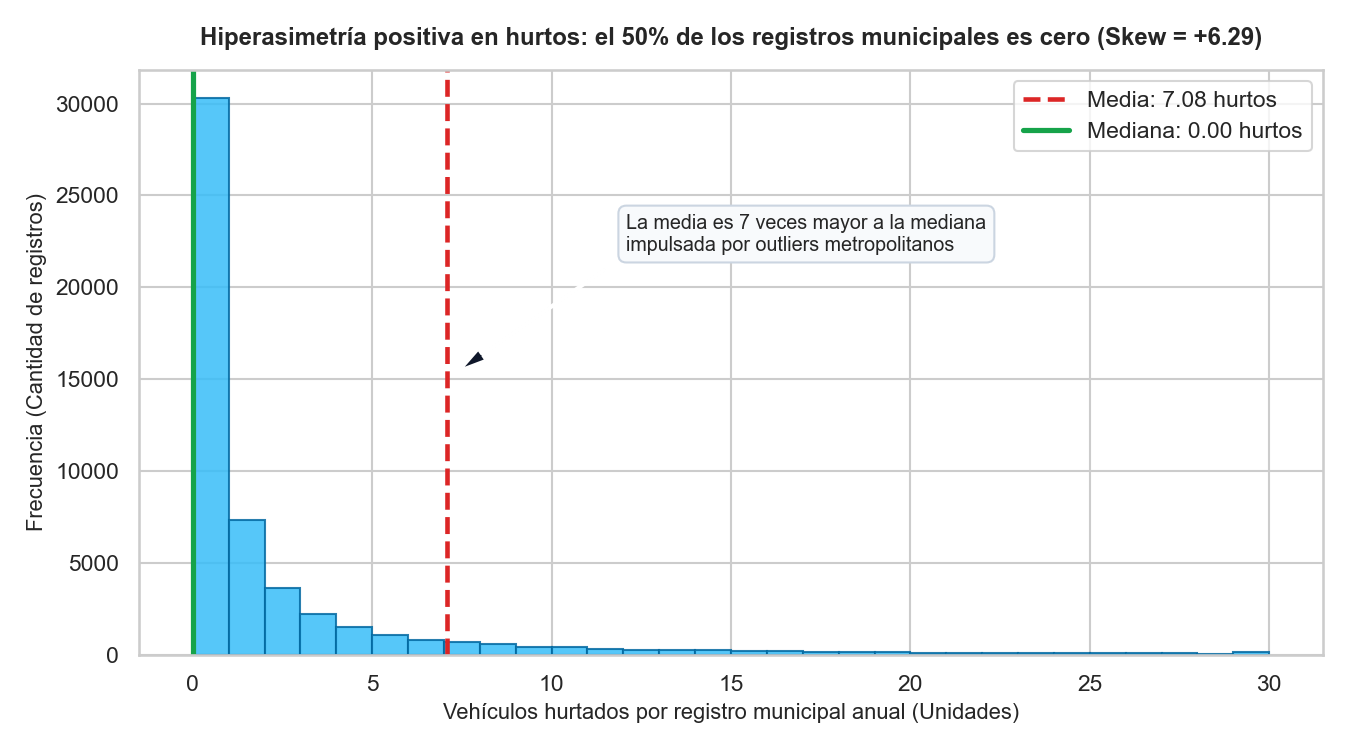

In [9]:
display(Image(filename="figuras/fig_hist_hurtos.png"))

### 8.2 Figura 2: Boxplot y Cuantificación de Outliers
**Lectura:** El 50% central de los registros se ubica entre 0 y 2 hurtos. Los 8,344 outliers se ilustran claramente sobre el eje horizontal sin deformar la caja.

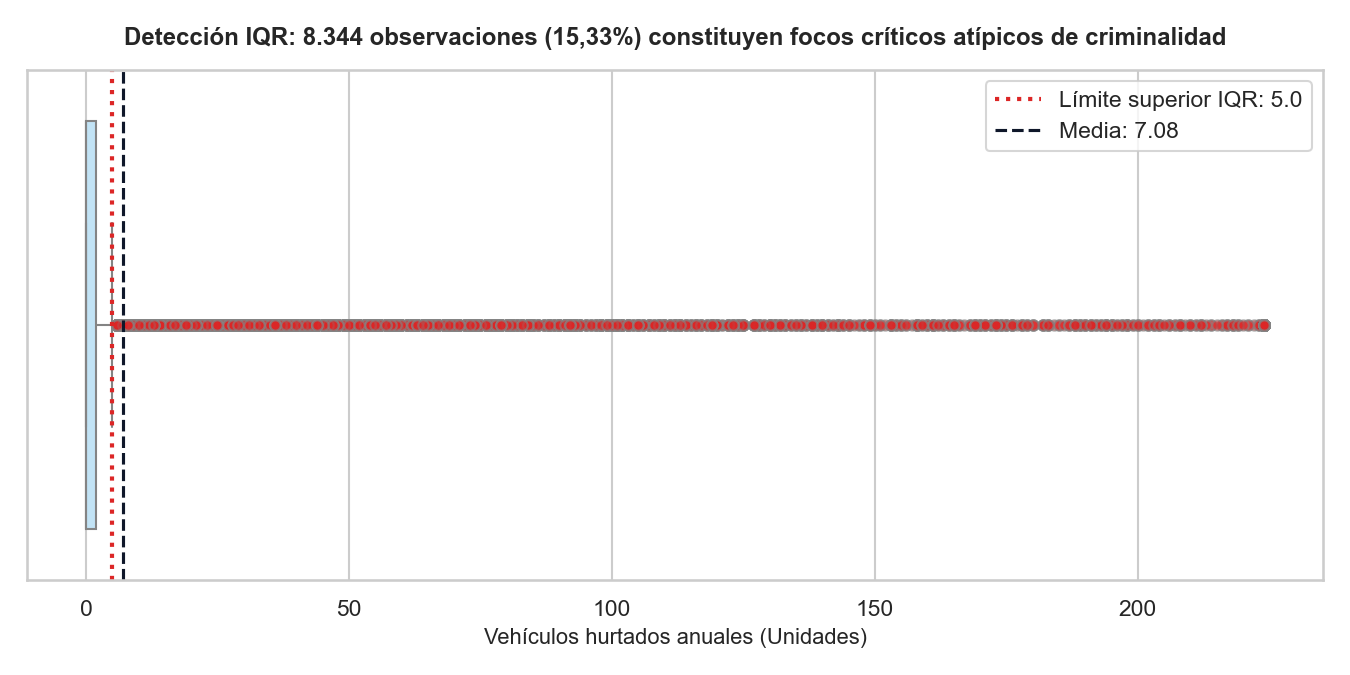

In [10]:
display(Image(filename="figuras/fig_box_hurtos.png"))

### 8.3 Figura 3: Gráfico de Barras Ordenado por Departamento y Tipo
**Lectura:** Antioquia y Valle concentran la mayor criminalidad, y las motocicletas superan ampliamente a los automotores en todos los focos principales.

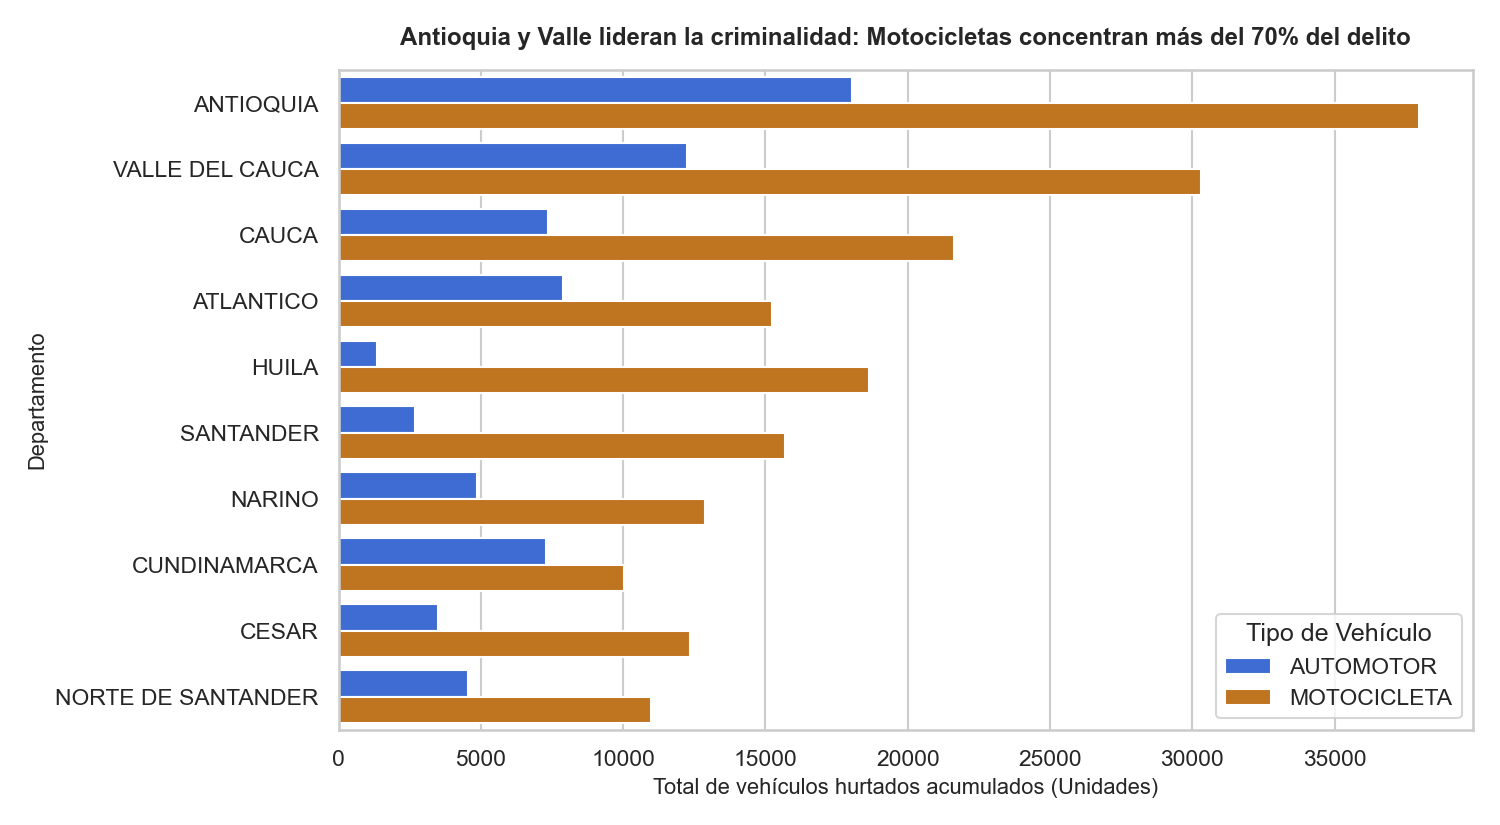

In [11]:
display(Image(filename="figuras/fig_barras_departamentos.png"))

### 8.4 Figura 4: Dispersión y Tendencia MCO (Hurto vs Recuperación)
**Lectura:** Relación fuerte ($r = 0.61$) que valida que el despliegue de recuperación de la Policía responde activamente a los focos de hurto.

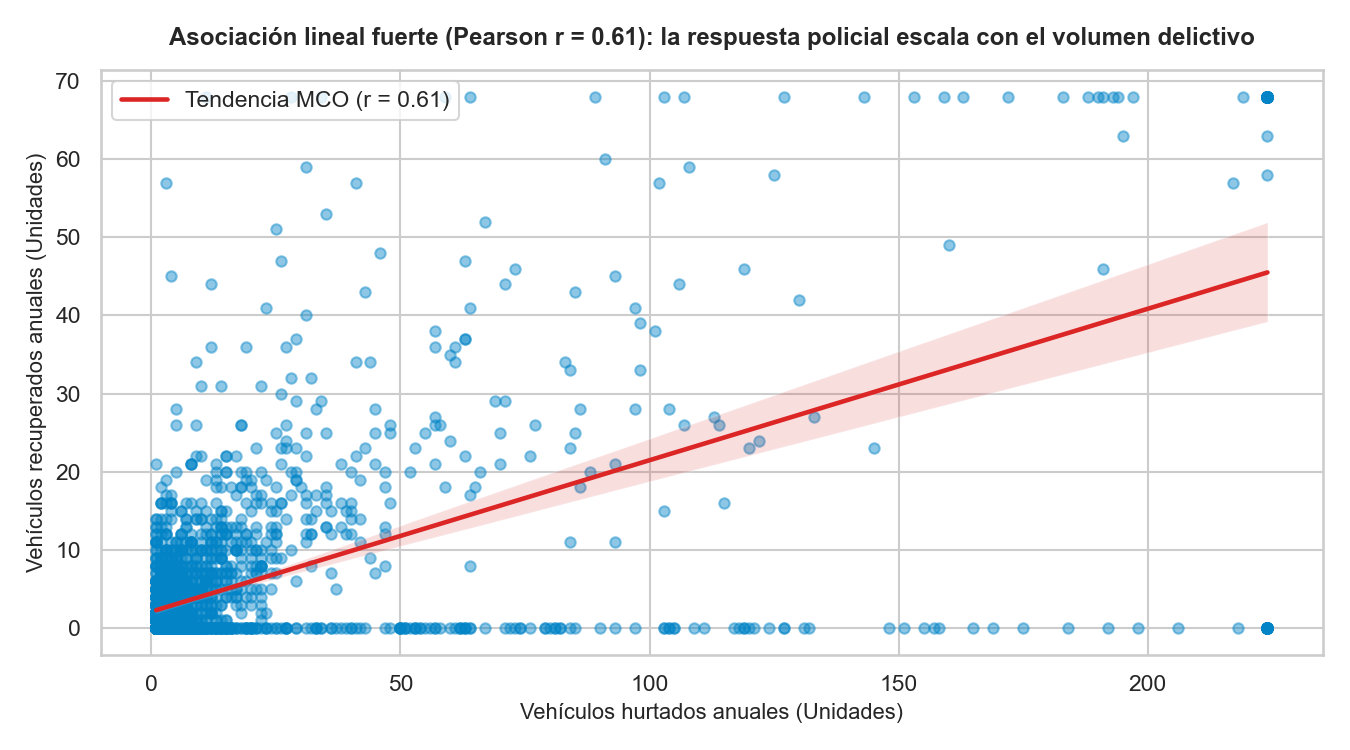

In [12]:
display(Image(filename="figuras/fig_scatter_hurto_vs_recuperacion.png"))

### 8.5 Figura 5: Heatmap de Correlaciones Numéricas
**Lectura:** Coeficientes de correlación anotados con paleta divergente centrada en cero.

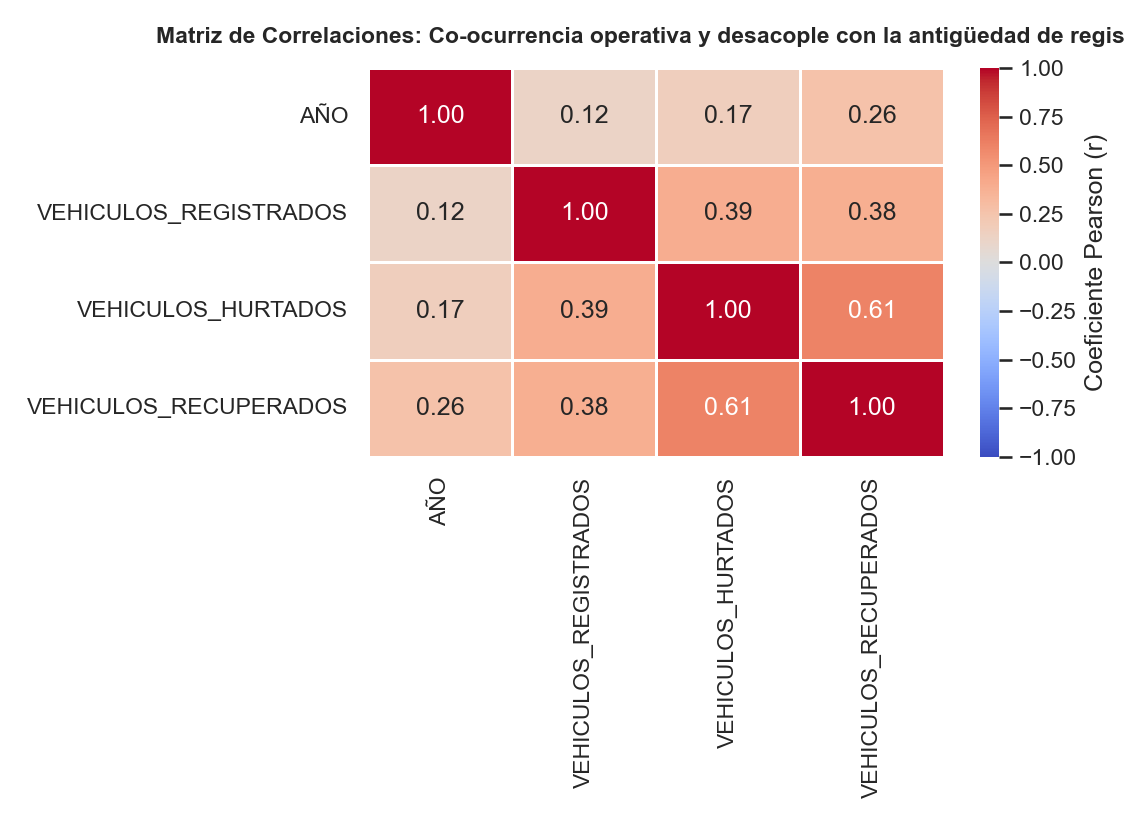

In [13]:
display(Image(filename="figuras/fig_heatmap_correlaciones.png"))

### 8.6 Figura 6: Matriz de Dispersión Multivariada (Pairplot)
**Lectura:** Densidades KDE en la diagonal y nubes de dispersión cruzadas entre todas las combinaciones de pares numéricos.

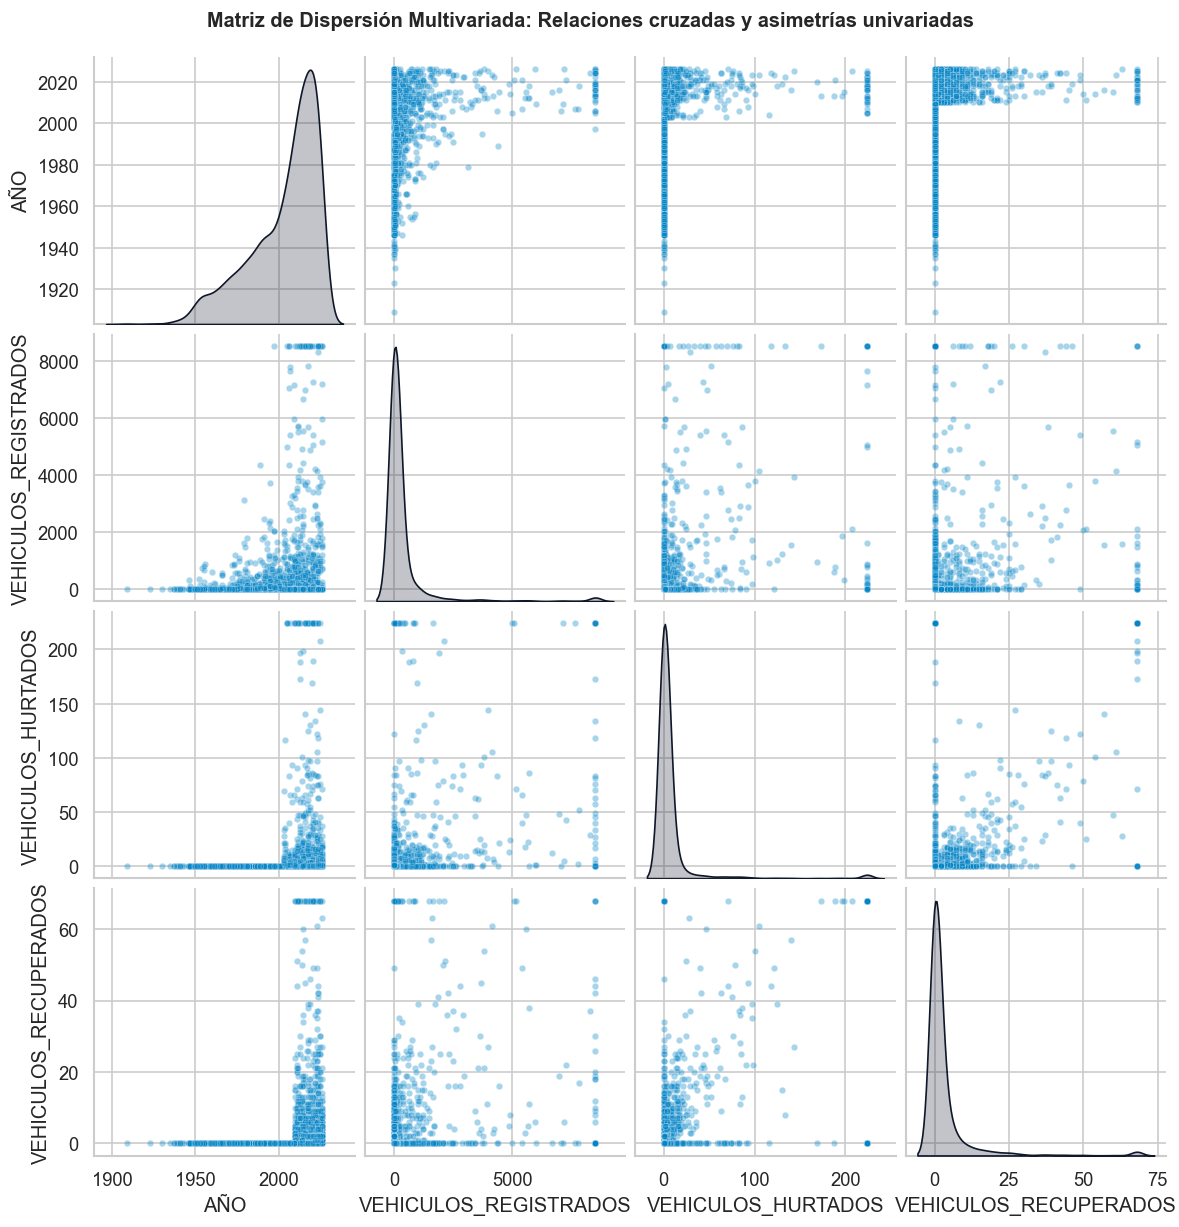

In [14]:
display(Image(filename="figuras/fig_matriz_dispersion.png"))

### 8.7 Figura 7 (Trabajo Independiente 1): Boxplot por Departamento y Tipo de Vehículo
**Lectura:** Comparativa del rango intercuartílico en los 6 departamentos críticos, mostrando la enorme dispersión en motocicletas.

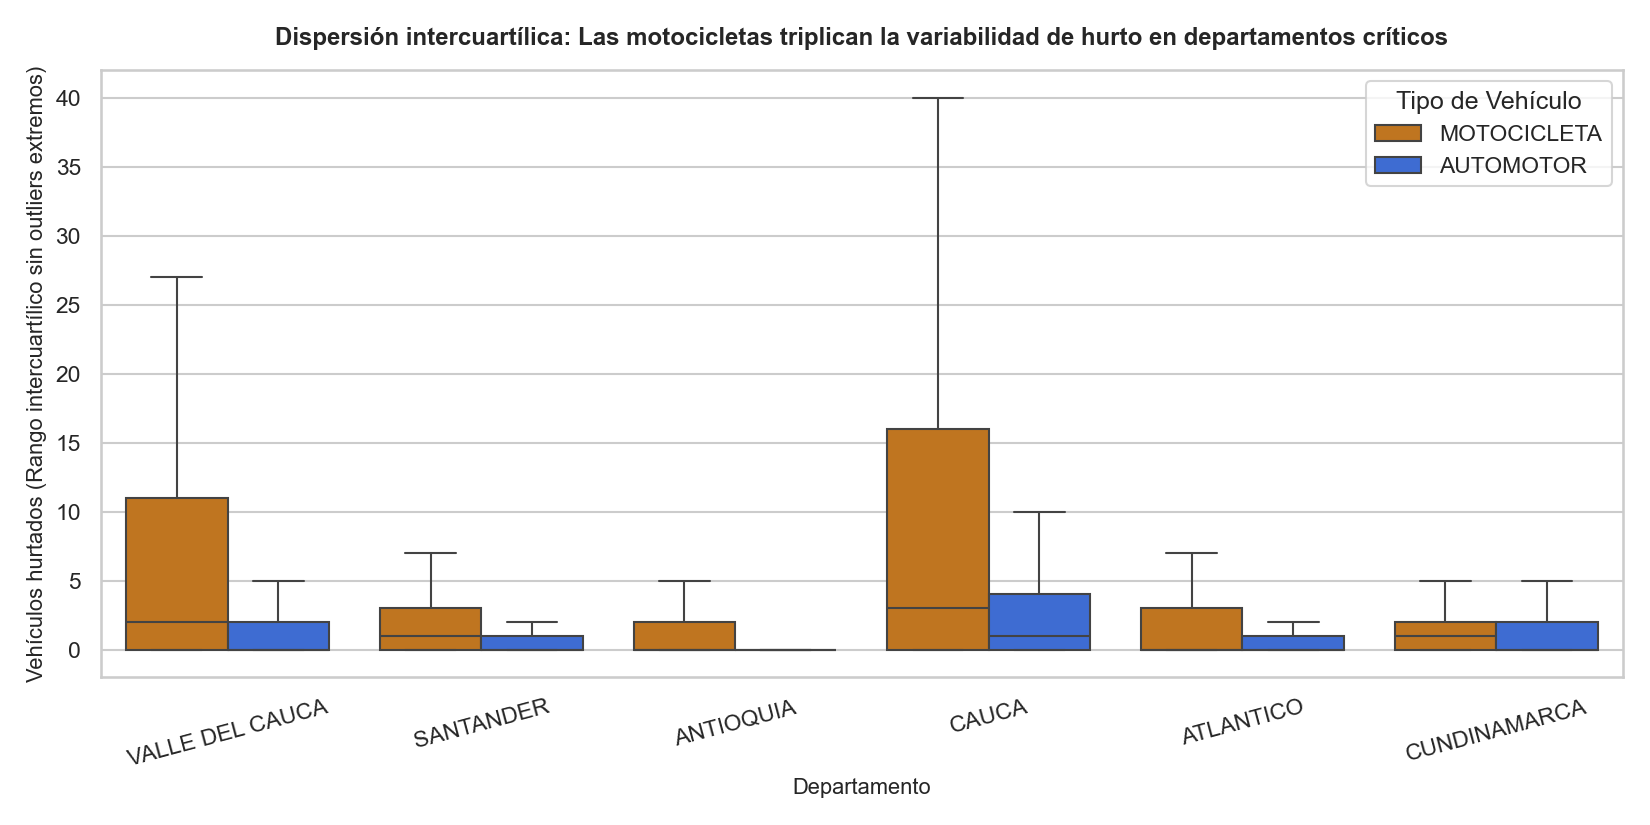

In [15]:
display(Image(filename="figuras/fig_box_hurto_tipo_vehiculo.png"))

### 8.8 Figura 8 (Trabajo Independiente 2): Tendencia Multianual de Tasa de Recuperación
**Lectura:** Revela una brecha persistente de efectividad donde la recuperación de motocicletas está permanentemente rezagada frente a la de automotores.

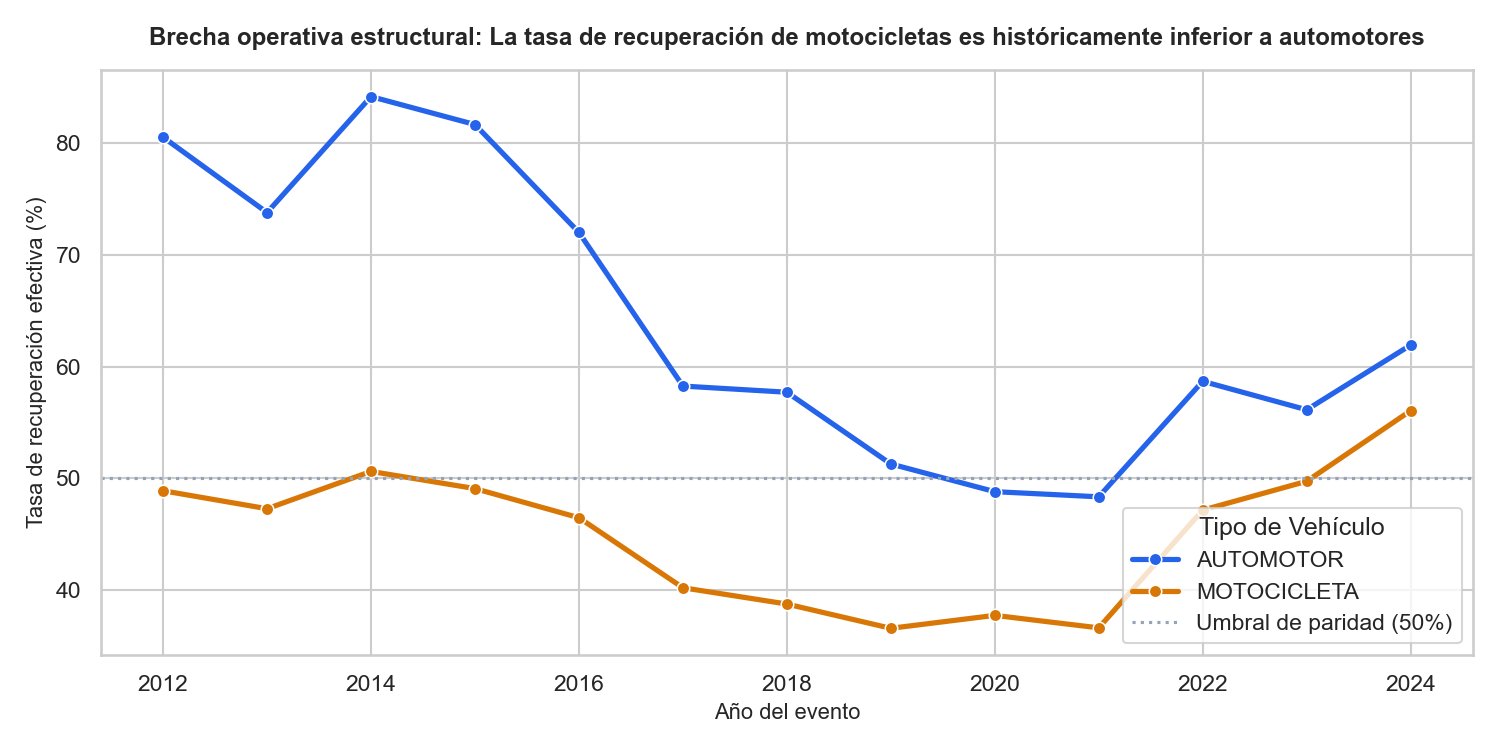

In [16]:
display(Image(filename="figuras/fig_tendencia_temporal_tasa_recuperacion.png"))

## 9. Hallazgos Accionables y Recomendaciones de Política Pública
Presentación de los 3 hallazgos centrales estructurados bajo el estándar exigido por el curso:
**Hallazgo + Evidencia Estadística + Acción Sugerida**.

In [17]:
eda.imprimir_resumen_ejecutivo()

RESUMEN EJECUTIVO · HALLAZGOS ACCIONABLES (ESTÁNDAR DEL CURSO)

HALLAZGO #1: Hiperconcentración Urbana y Falsa Representatividad de la Media
  • Evidencia Estadística: La asimetría de VEHICULOS_HURTADOS es +6.29 y la curtosis es 42.10. Mientras la media nacional es de 7.08 hurtos, la mediana es 0.00. El 15.33% de los registros (8,344 observaciones) superan el límite superior IQR (Q3 + 1.5×IQR = 5 hurtos), concentrados en las áreas metropolitanas de Medellín, Bogotá, Cali y Barranquilla.
  • Acción Sugerida       : Para reportes estratégicos y modelos de machine learning no supervisado (K-Means/PCA), debe descartarse la media aritmética y adoptarse la mediana como centro de referencia, aplicando escalamiento robusto (RobustScaler) o segmentación previa por categoría municipal.

HALLAZGO #2: Vulnerabilidad Desproporcionada y Brecha Operativa en Motocicletas
  • Evidencia Estadística: Las motocicletas representan el 75.7% de los hurtos totales en Colombia (291,905 casos frente a 93,589 au